# Avaluació Inicial del dataset 'Regensburg Pedriatic Appendicitis'

In [196]:
#llibreries
#!pip install pandas --upgrade  --quiet
#!pip install numpy --upgrade  --quiet
#!pip install scipy --upgrade  --quiet
#!pip install statsmodels --upgrade  --quiet
#!pip install scikit-learn --upgrade  --quiet
#!pip install missingno --upgrade  --quiet
!pip install apafib --upgrade --quiet

In [197]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

In [198]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split,  KFold, cross_val_score
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.precision', 3)

## 1. Importació de les dades

In [199]:
dades = pd.read_csv("../dataset.csv") #eliminem variables que no volem
dades.drop(columns=['Length_of_Stay', 'Management', 'Severity', 'Diagnosis_Presumptive', 'Alvarado_Score', 'Paedriatic_Appendicitis_Score', 'US_Number'], inplace=True)

cols = list(dades.columns) #reordenem per tindre Diagnosis com el primer atribut
cols.remove('Diagnosis')
cols.insert(0, 'Diagnosis')
dades = dades.reindex(columns=cols)

dades.head()
dades.shape

,Diagnosis,Age,BMI,Sex,Height,Weight,Appendix_on_US,Appendix_Diameter,Migratory_Pain,Lower_Right_Abd_Pain,Contralateral_Rebound_Tenderness,Coughing_Pain,Nausea,Loss_of_Appetite,Body_Temperature,WBC_Count,Neutrophil_Percentage,Segmented_Neutrophils,Neutrophilia,RBC_Count,Hemoglobin,RDW,Thrombocyte_Count,Ketones_in_Urine,RBC_in_Urine,WBC_in_Urine,CRP,Dysuria,Stool,Peritonitis,Psoas_Sign,Ipsilateral_Rebound_Tenderness,US_Performed,Free_Fluids,Appendix_Wall_Layers,Target_Sign,Appendicolith,Perfusion,Perforation,Surrounding_Tissue_Reaction,Appendicular_Abscess,Abscess_Location,Pathological_Lymph_Nodes,Lymph_Nodes_Location,Bowel_Wall_Thickening,Conglomerate_of_Bowel_Loops,Ileus,Coprostasis,Meteorism,Enteritis,Gynecological_Findings
0,appendicitis,12.68,16.9,female,148.0,37.0,yes,7.1,no,yes,yes,no,no,yes,37.0,7.7,68.2,NaN,no,5.27,14.8,12.2,254.0,++,+,no,0.0,no,normal,no,yes,no,yes,no,intact,NaN,suspected,NaN,no,yes,no,NaN,yes,reUB,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,no appendicitis,14.10,31.9,male,147.0,69.5,no,NaN,yes,yes,yes,no,no,yes,36.9,8.1,64.8,NaN,no,5.26,15.7,12.7,151.0,no,no,no,3.0,yes,normal,no,yes,no,yes,no,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,yes,NaN,NaN
2,no appendicitis,14.14,23.3,female,163.0,62.0,no,NaN,no,yes,yes,no,no,no,36.6,13.2,74.8,NaN,no,3.98,11.4,12.2,300.0,no,no,no,3.0,no,constipation,no,yes,no,yes,no,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,yes,yes,NaN
3,no appendicitis,16.37,20.6,female,165.0,56.0,no,NaN,yes,yes,no,no,yes,yes,36.0,11.4,63.0,NaN,no,4.64,13.6,13.2,258.0,no,no,no,0.0,yes,normal,no,yes,no,yes,no,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,yes,reUB,NaN,NaN,NaN,NaN,NaN,yes,NaN
4,appendicitis,11.08,16.9,female,163.0,45.0,yes,7.0,no,yes,yes,yes,yes,yes,36.9,8.1,44.0,NaN,no,4.44,12.6,13.6,311.0,no,no,no,0.0,no,constipation,no,yes,no,yes,no,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,yes,reUB,NaN,NaN,NaN,NaN,NaN,yes,NaN


(782, 51)

## 2. Visualització bàsica de les dades

### 2.1 - Diferenciació entre numèriques i categòriques

In [200]:
numerical_columns = ['Age', 'BMI', 'Height', 'Weight', 'Appendix_Diameter', 'Body_Temperature', 'Segmented_Neutrophils', 'WBC_Count', 'Neutrophil_Percentage', 'RBC_Count', 'Hemoglobin', 'RDW', 'Thrombocyte_Count', 'CRP']
categorical_columns = [c for c in dades.columns if c not in numerical_columns]

for column in categorical_columns:
    dades[column] = dades[column].astype('category')

numerical_columns

['Age',
 'BMI',
 'Height',
 'Weight',
 'Appendix_Diameter',
 'Body_Temperature',
 'Segmented_Neutrophils',
 'WBC_Count',
 'Neutrophil_Percentage',
 'RBC_Count',
 'Hemoglobin',
 'RDW',
 'Thrombocyte_Count',
 'CRP']

### 2.2 - Descripció estadística

In [201]:
dades.describe(include='all').T[ ['count', 'unique', 'mean', 'std', 'min', 'max'] ]

,count,unique,mean,std,min,max
Diagnosis,780,2,NaN,NaN,NaN,NaN
Age,781.0,NaN,24.145,357.654,0.0,10006.0
BMI,755.0,NaN,44.905,714.389,7.828,19648.0
Sex,780,2,NaN,NaN,NaN,NaN
Height,756.0,NaN,148.017,19.732,53.0,192.0
Weight,779.0,NaN,43.173,17.391,3.96,103.0
Appendix_on_US,777,2,NaN,NaN,NaN,NaN
Appendix_Diameter,498.0,NaN,7.763,2.537,2.7,17.0
Migratory_Pain,773,2,NaN,NaN,NaN,NaN
Lower_Right_Abd_Pain,774,2,NaN,NaN,NaN,NaN


In [202]:
#eliminem dos casos Nan de Diagnosis
dades.dropna(subset=['Diagnosis'], inplace=True)
dades.reset_index(drop=True, inplace=True) #per si de cas

#outliers clars a age i bmi
dades['Age'] = dades['Age'].replace(10006, np.nan)
dades['BMI'] = dades['BMI'].replace(19648, np.nan)

dades.loc[: , ['Age', 'BMI'] ].describe().T[ ['count', 'mean', 'std', 'min', 'max'] ]

,count,mean,std,min,max
Age,779.0,11.344,3.532,0.000,18.360
BMI,753.0,18.904,4.391,7.828,38.156


### 2.3 - Histogrames

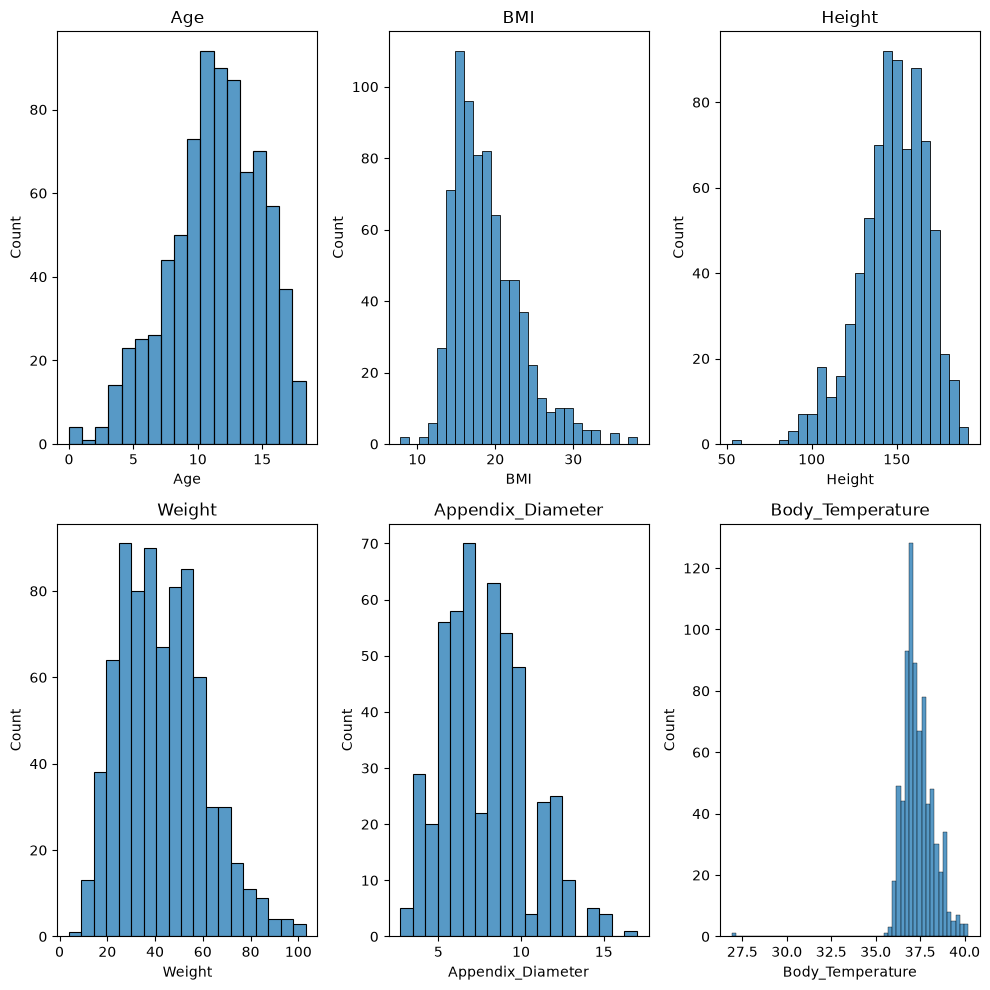

In [203]:
# Numèrics
fig, axes = plt.subplots(2, 3, figsize=(10,10) )
for i, c in enumerate(numerical_columns[:6]):
    ax = axes.reshape(-1)[i]
    histograma = sns.histplot(x=c, data=dades,ax=ax)
    t = ax.set_title(c)
plt.tight_layout()

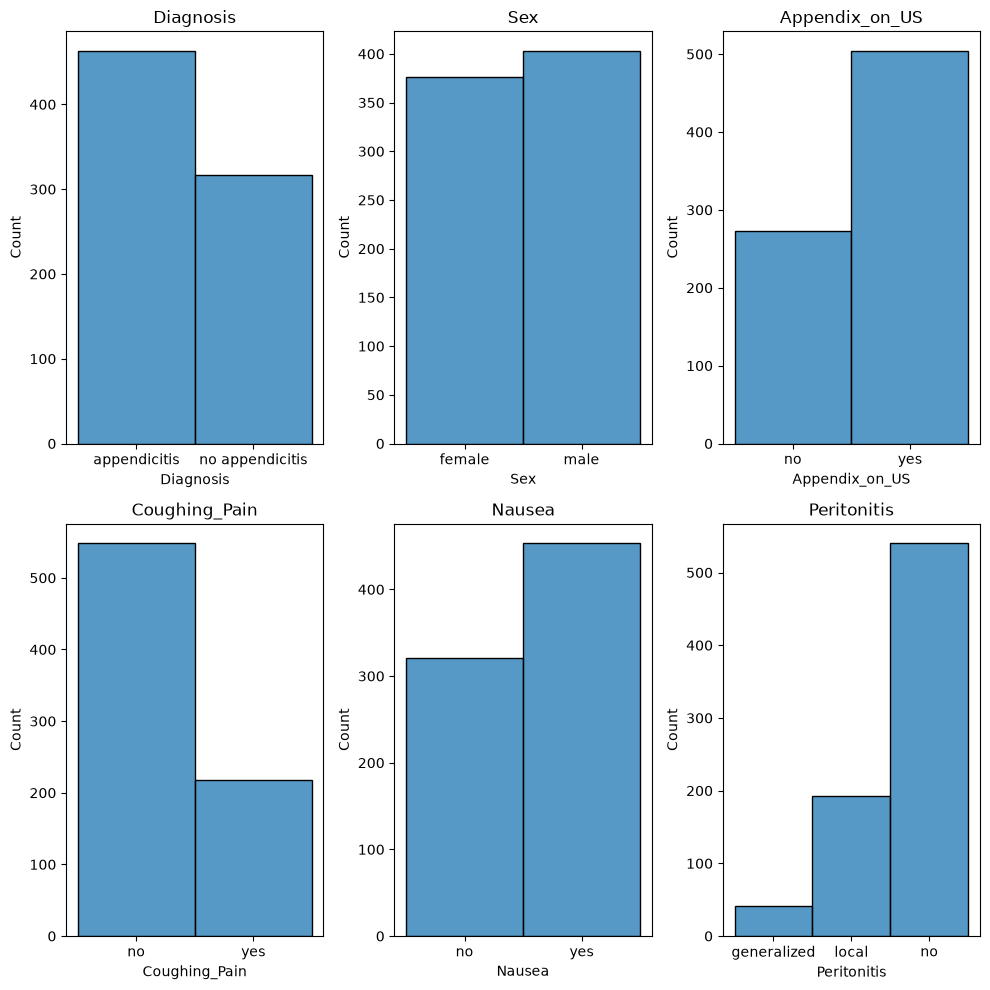

In [204]:
# Categòrics
fig, axes = plt.subplots(2, 3, figsize=(10,10) )
for i, c in enumerate( ['Diagnosis', 'Sex', 'Appendix_on_US', 'Coughing_Pain', 'Nausea', 'Peritonitis' ] ):
    ax = axes.reshape(-1)[i]
    count = sns.histplot(x=c, data=dades,ax=ax)
    t = ax.set_title(c)
plt.tight_layout()

### 2.4 - Boxplots

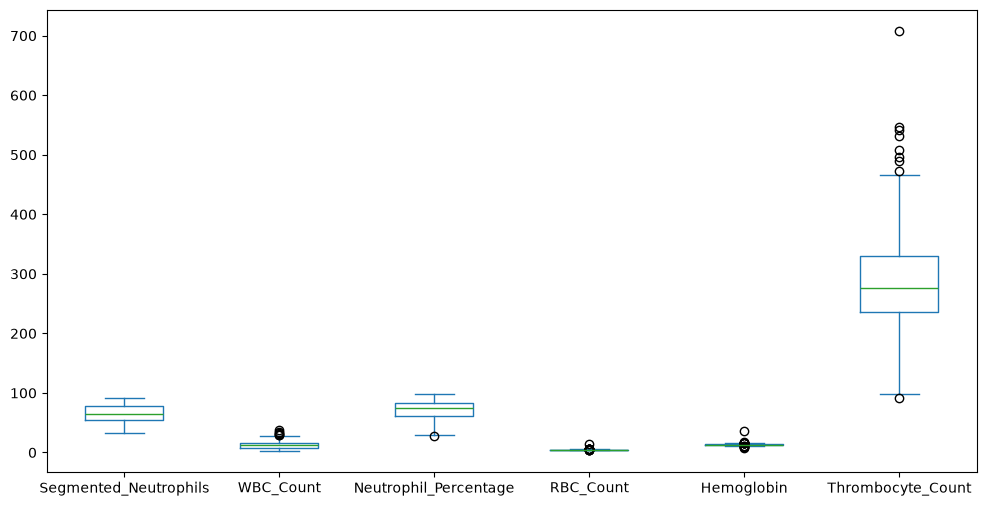

In [205]:
dades.loc[:, ['Segmented_Neutrophils', 'WBC_Count', 'Neutrophil_Percentage', 'RBC_Count', 'Hemoglobin', 'Thrombocyte_Count'] ].plot.box(figsize=(12,6));

### 2.5 - Comparació amb variable objectiu

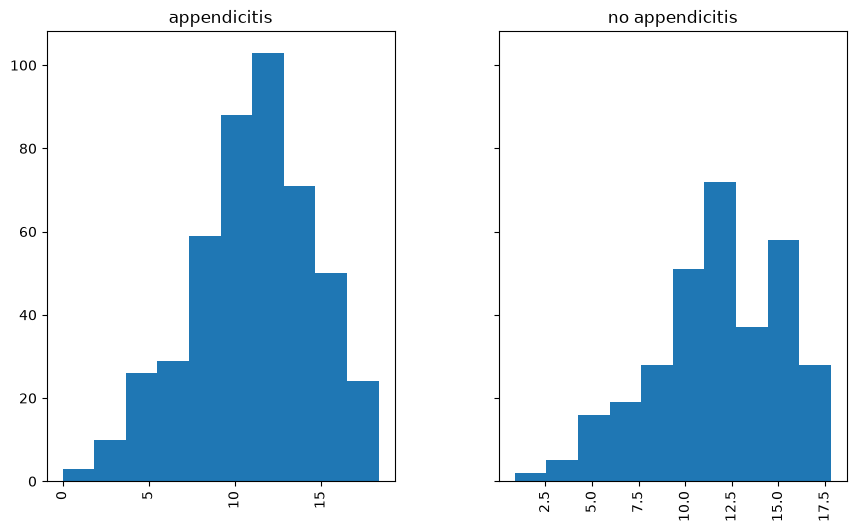

In [206]:
# Diagnosis vs Edat
dades.hist(column='Age',by='Diagnosis',bins=10, sharey=True, figsize=(10,6), layout=(1,2));

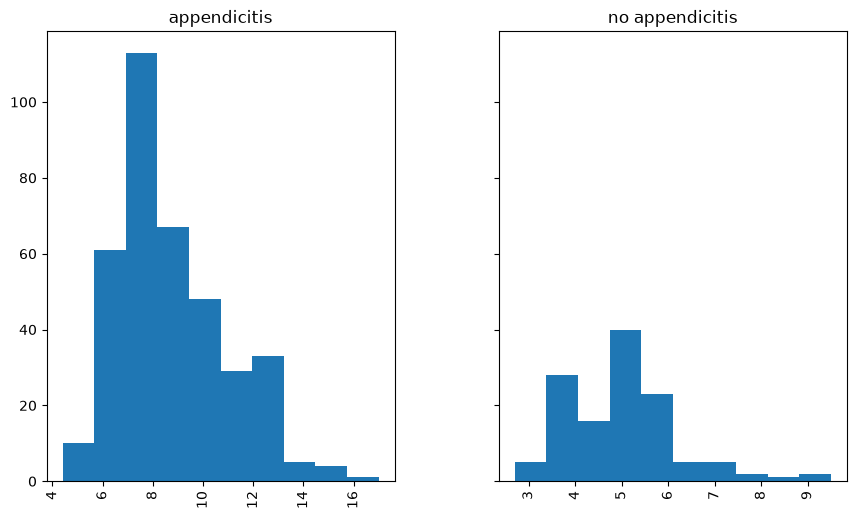

In [207]:
# Diagnosis vs Appendix_Diameter
dades.hist(column='Appendix_Diameter',by='Diagnosis',bins=10, sharey=True, figsize=(10,6), layout=(1,2));

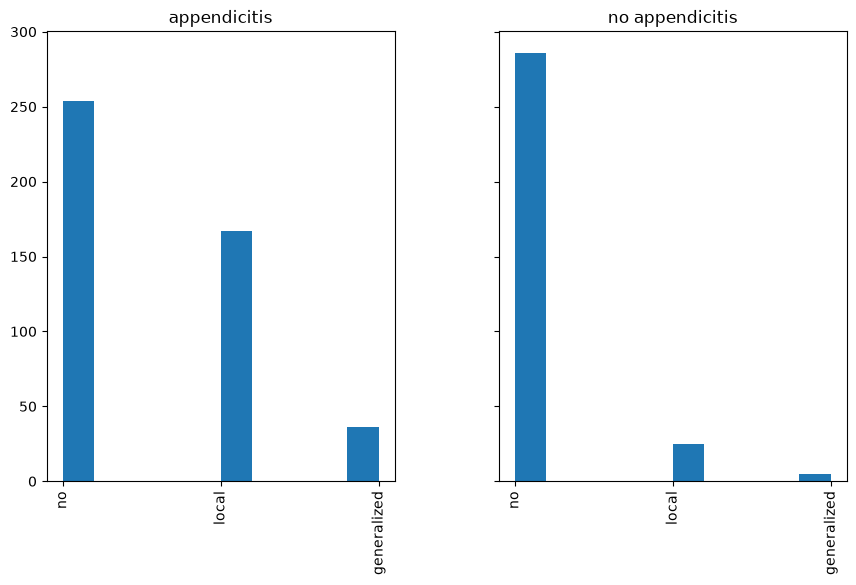

In [208]:
# Diagnosis vs Peritonitis
dades.hist(column='Peritonitis',by='Diagnosis',bins=10, sharey=True, figsize=(10,6), layout=(1,2));

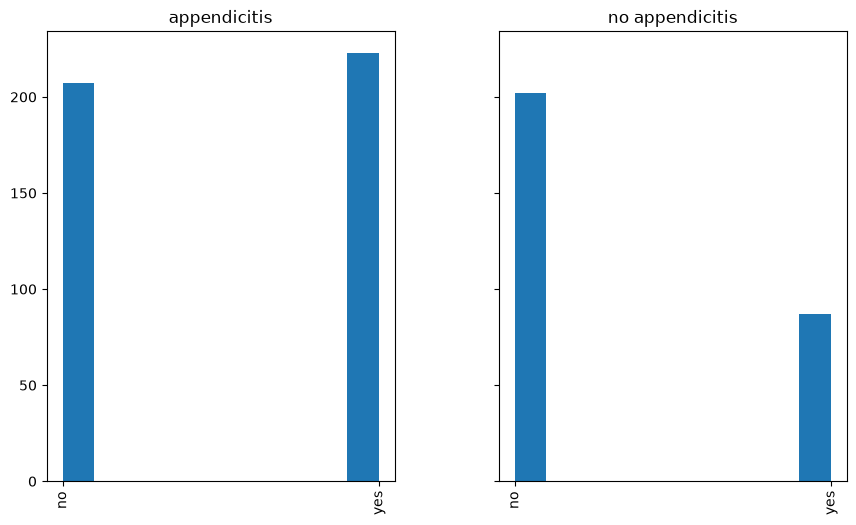

In [209]:
# Diagnosis vs Free_Fluids
dades.hist(column='Free_Fluids',by='Diagnosis',bins=10, sharey=True, figsize=(10,6), layout=(1,2));

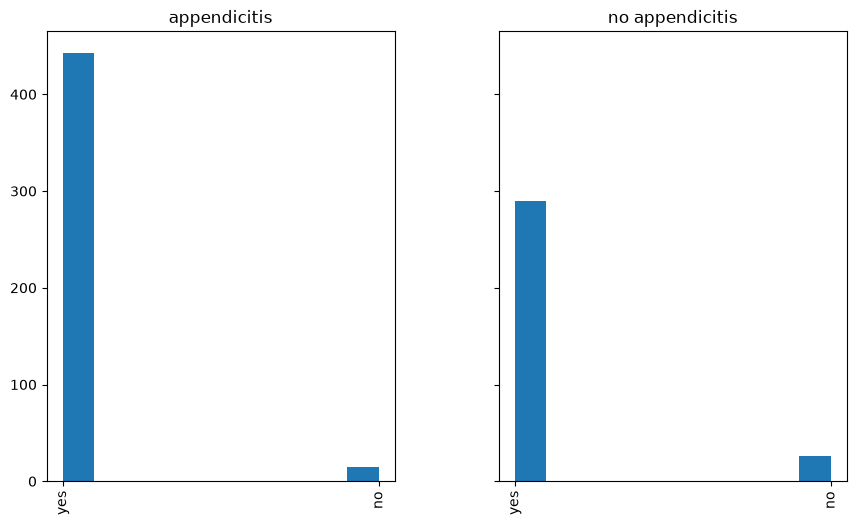

In [210]:
# Diagnosis vs Lower_Right_Abd_Pain
dades.hist(column='Lower_Right_Abd_Pain',by='Diagnosis',bins=10, sharey=True, figsize=(10,6), layout=(1,2));

Veiem clarament que la variable *Lower_Right_Abd_Pain* té un fort impacte en si el pacient té o no apendicitis.

### 2.6 - Comprovació de l'atribut Appendix_on_US

Volem comprovar que l'atribut *Appendix_on_US* no impliqui directament que quan pren valor de *no* llavors el pacient mai tindrà apendicitis. Es pot confirmar la nostra hipòtesi al veure que hi ha 82 casos on els doctors van dir que no hi havia apèndix però després es va veure que el pacient patia l'enfermetat.

In [211]:
pd.crosstab(dades['Appendix_on_US'], dades['Diagnosis'])

Diagnosis,appendicitis,no appendicitis
Appendix_on_US,,
no,82,191
yes,378,126


### 2.7 - Matriu de Correlacions

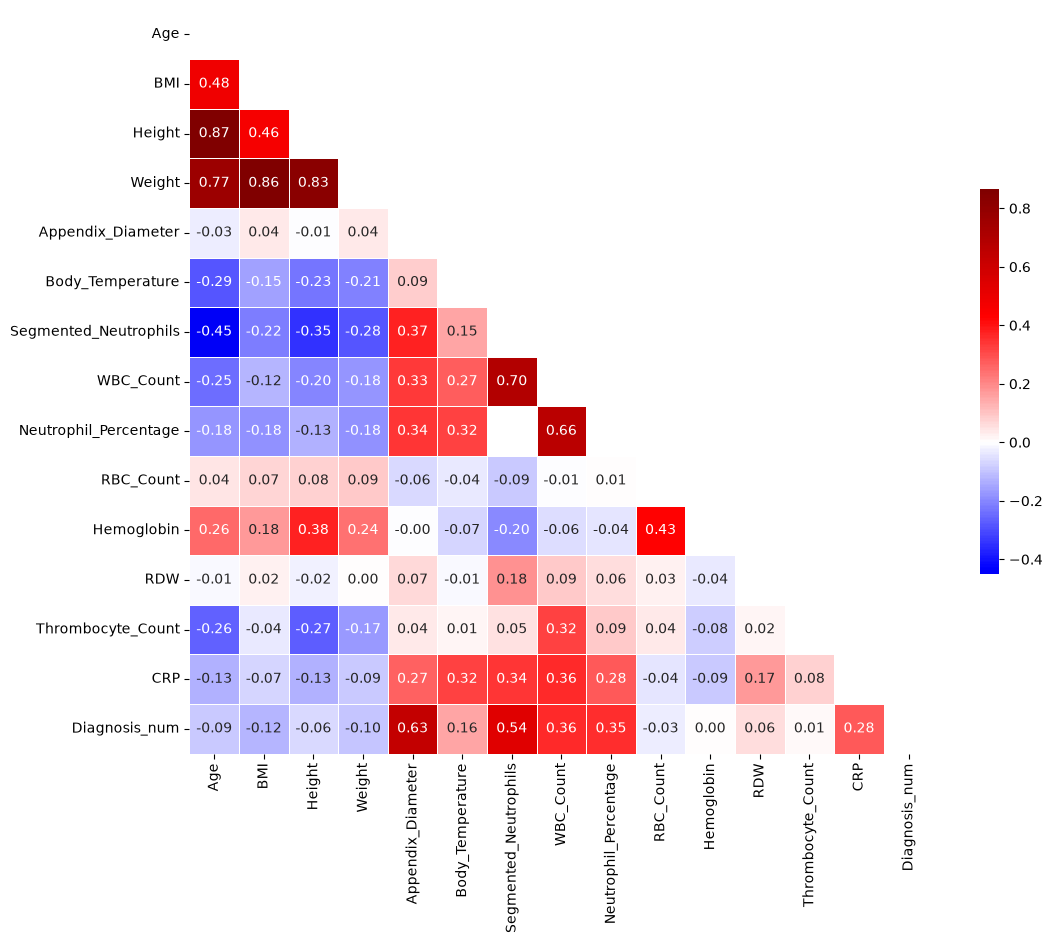

In [212]:
# només numèriques i amb Diagnosis
dades_corr = dades[numerical_columns].copy()
dades_corr['Diagnosis_num'] = (dades['Diagnosis'] == 'appendicitis').astype(int)

corr = dades_corr.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.subplots(figsize=(12, 10))
sns.heatmap(corr, mask=mask, cmap='seismic',  center=0, square=True, annot=True, fmt=".2f", linewidths=.5, cbar_kws={"shrink": .5});

## 3. Model Bàsic amb Regressió Logística

### 3.1 - Valors Nan

In [213]:
dades.isna().sum().sort_values(ascending=False)

Abscess_Location                    767
Gynecological_Findings              754
Conglomerate_of_Bowel_Loops         737
Segmented_Neutrophils               726
Ileus                               720
Perfusion                           717
Enteritis                           714
Appendicolith                       711
Coprostasis                         709
Perforation                         699
Appendicular_Abscess                695
Bowel_Wall_Thickening               681
Lymph_Nodes_Location                659
Target_Sign                         642
Meteorism                           640
Pathological_Lymph_Nodes            577
Appendix_Wall_Layers                562
Surrounding_Tissue_Reaction         528
Appendix_Diameter                   282
RBC_in_Urine                        204
Ketones_in_Urine                    198
WBC_in_Urine                        197
Ipsilateral_Rebound_Tenderness      161
Neutrophil_Percentage               101
Free_Fluids                          61


Podem comprovar com hi ha atributs amb pràcticament tot són valors Nan. Hem decidit treure aquests atributs ja que fer una imputació només aportaria soroll.

In [214]:
dades.drop(columns=['Abscess_Location', 'Gynecological_Findings', 'Conglomerate_of_Bowel_Loops', 'Segmented_Neutrophils', 'Ileus', 'Perfusion', 'Enteritis', 'Appendicolith', 'Coprostasis', 'Perforation', 'Appendicular_Abscess', 'Bowel_Wall_Thickening', 'Lymph_Nodes_Location', 'Target_Sign', 'Meteorism', 'Pathological_Lymph_Nodes', 'Appendix_Wall_Layers', 'Surrounding_Tissue_Reaction'], inplace=True)

### 3.2 - Divisió en Train i Test

In [215]:
X = dades.iloc[:, 1:] #treiem Diagnosis
y = dades.iloc[:, 0] #agafem Diagnosis

X.shape, y.shape[0]

((780, 32), 780)

In [216]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"Mida dels atributs train: {X_train.shape}")
print(f"Mida de la variable objectiu train: {y_train.shape[0]}\n")

print(f"Mida dels atributs test: {X_test.shape}")
print(f"Mida de la variable objectiu test: {y_test.shape[0]}")

Mida dels atributs train: (546, 32)
Mida de la variable objectiu train: 546

Mida dels atributs test: (234, 32)
Mida de la variable objectiu test: 234


### 3.3 - Preprocessat bàsic

In [217]:
def treure_nan(dades, train):
    X = dades
    
    #Nan 
    X.loc[ X['Appendix_Diameter'].isna(), 'Appendix_Diameter' ] = train['Appendix_Diameter'].median();
    X.loc[ X['RBC_in_Urine'].isna(), 'RBC_in_Urine' ] = train['RBC_in_Urine'].mode()[0];
    X.loc[ X['Ketones_in_Urine'].isna(), 'Ketones_in_Urine' ] = train['Ketones_in_Urine'].mode()[0];
    X.loc[ X['WBC_in_Urine'].isna(), 'WBC_in_Urine' ] = train['WBC_in_Urine'].mode()[0];
    X.loc[ X['Ipsilateral_Rebound_Tenderness'].isna(), 'Ipsilateral_Rebound_Tenderness' ] = train['Ipsilateral_Rebound_Tenderness'].mode()[0];
    X.loc[ X['Neutrophil_Percentage'].isna(), 'Neutrophil_Percentage' ] = train['Neutrophil_Percentage'].median();
    X.loc[ X['Free_Fluids'].isna(), 'Free_Fluids' ] = train['Free_Fluids'].mode()[0];
    X.loc[ X['Neutrophilia'].isna(), 'Neutrophilia' ] = train['Neutrophilia'].mode()[0];
    X.loc[ X['Psoas_Sign'].isna(), 'Psoas_Sign' ] = train['Psoas_Sign'].mode()[0];
    X.loc[ X['Dysuria'].isna(), 'Dysuria' ] = train['Dysuria'].mode()[0];
    X.loc[ X['BMI'].isna(), 'BMI' ] = train['BMI'].median();
    X.loc[ X['Height'].isna(), 'Height' ] = train['Height'].median();
    X.loc[ X['RDW'].isna(), 'RDW' ] = train['RDW'].median();
    X.loc[ X['Hemoglobin'].isna(), 'Hemoglobin' ] = train['Hemoglobin'].median();
    X.loc[ X['Thrombocyte_Count'].isna(), 'Thrombocyte_Count' ] = train['Thrombocyte_Count'].median();
    X.loc[ X['RBC_Count'].isna(), 'RBC_Count' ] = train['RBC_Count'].median();
    X.loc[ X['Stool'].isna(), 'Stool' ] = train['Stool'].mode()[0];
    X.loc[ X['Coughing_Pain'].isna(), 'Coughing_Pain' ] = train['Coughing_Pain'].mode()[0];
    X.loc[ X['Contralateral_Rebound_Tenderness'].isna(), 'Contralateral_Rebound_Tenderness' ] = train['Contralateral_Rebound_Tenderness'].mode()[0];
    X.loc[ X['CRP'].isna(), 'CRP' ] = train['CRP'].median();
    X.loc[ X['Loss_of_Appetite'].isna(), 'Loss_of_Appetite' ] = train['Loss_of_Appetite'].mode()[0];
    X.loc[ X['Migratory_Pain'].isna(), 'Migratory_Pain' ] = train['Migratory_Pain'].mode()[0];
    X.loc[ X['Peritonitis'].isna(), 'Peritonitis' ] = train['Peritonitis'].mode()[0];
    X.loc[ X['Nausea'].isna(), 'Nausea' ] = train['Nausea'].mode()[0];
    X.loc[ X['Lower_Right_Abd_Pain'].isna(), 'Lower_Right_Abd_Pain' ] = train['Lower_Right_Abd_Pain'].mode()[0];
    X.loc[ X['Body_Temperature'].isna(), 'Body_Temperature' ] = train['Body_Temperature'].median();
    X.loc[ X['WBC_Count'].isna(), 'WBC_Count' ] = train['WBC_Count'].median();
    X.loc[ X['Appendix_on_US'].isna(), 'Appendix_on_US' ] = train['Appendix_on_US'].mode()[0];
    X.loc[ X['US_Performed'].isna(), 'US_Performed' ] = train['US_Performed'].mode()[0];
    X.loc[ X['Weight'].isna(), 'Weight' ] = train['Weight'].median();
    X.loc[ X['Sex'].isna(), 'Sex' ] = train['Sex'].mode()[0];
    X.loc[ X['Age'].isna(), 'Age' ] = train['Age'].median();

    return X

In [218]:
def preprocessat_basic(X, y, train):
    X_clean = treure_nan(X, train)
    y_clean = y
    
    categorical_columns = X_clean.dtypes[X_clean.dtypes == 'category'].index.values
    
    #one-hot encoding
    for c in categorical_columns:
        dummies = pd.get_dummies(X_clean[c], drop_first=True, prefix=c, prefix_sep='_') # generem columns
        X_clean = pd.concat([X_clean, dummies], axis=1) #ajuntem columns
        X_clean.drop(columns=[c], inplace=True) #treiem original

    return X_clean, y_clean

In [219]:
train = X_train.copy()
X_train, y_train = preprocessat_basic(X_train, y_train, train)
X_test, y_test = preprocessat_basic(X_test, y_test, train)

print(f"Mida dels atributs train: {X_train.shape}")
print(f"Mida de la variable objectiu train: {y_train.shape[0]}\n")

print(f"Mida dels atributs test: {X_test.shape}")
print(f"Mida de la variable objectiu test: {y_test.shape[0]}")

Mida dels atributs train: (546, 42)
Mida de la variable objectiu train: 546

Mida dels atributs test: (234, 42)
Mida de la variable objectiu test: 234


In [220]:
X_train.head()

,Age,BMI,Height,Weight,Appendix_Diameter,Body_Temperature,WBC_Count,Neutrophil_Percentage,RBC_Count,Hemoglobin,RDW,Thrombocyte_Count,CRP,Sex_male,Appendix_on_US_yes,Migratory_Pain_yes,Lower_Right_Abd_Pain_yes,Contralateral_Rebound_Tenderness_no,Contralateral_Rebound_Tenderness_yes,Coughing_Pain_yes,Nausea_yes,Loss_of_Appetite_yes,Neutrophilia_yes,Ketones_in_Urine_++,Ketones_in_Urine_+++,Ketones_in_Urine_no,RBC_in_Urine_++,RBC_in_Urine_+++,RBC_in_Urine_no,WBC_in_Urine_++,WBC_in_Urine_+++,WBC_in_Urine_no,Dysuria_yes,"Stool_constipation, diarrhea",Stool_diarrhea,Stool_normal,Peritonitis_local,Peritonitis_no,Psoas_Sign_yes,Ipsilateral_Rebound_Tenderness_yes,US_Performed_yes,Free_Fluids_yes
24,15.920,21.900,180.0,71.0,7.00,37.0,5.2,62.0,4.69,14.3,11.7,197.0,1.0,True,True,False,True,True,False,False,False,False,False,False,False,True,False,False,True,False,False,True,False,False,False,True,False,True,False,False,True,False
635,10.579,16.837,140.0,33.0,10.00,38.2,19.8,77.0,4.79,13.1,12.3,257.0,185.0,True,True,False,True,False,True,True,True,True,True,False,False,True,False,False,True,False,False,True,False,False,False,True,True,False,True,False,True,True
622,15.069,32.184,174.5,98.0,12.00,36.6,7.5,58.4,4.98,14.0,14.6,290.0,1.0,True,True,True,True,True,False,False,True,False,False,False,False,True,False,False,True,False,False,True,False,False,True,False,False,True,True,False,True,True
334,9.194,15.432,144.0,32.0,7.50,37.8,13.6,79.2,4.93,12.8,14.1,302.0,0.0,False,True,True,True,False,True,True,True,True,True,False,False,True,False,False,False,False,False,True,False,False,False,False,False,True,True,True,True,False
363,8.580,18.062,170.0,52.2,7.75,36.8,9.1,68.1,4.11,12.6,11.6,307.0,4.0,False,False,False,True,True,False,False,False,True,False,False,True,False,True,False,False,True,False,False,False,False,False,True,False,True,False,False,True,False


In [221]:
X_train.isna().sum().sort_values(ascending=False)

Age                                     0
BMI                                     0
Height                                  0
Weight                                  0
Appendix_Diameter                       0
Body_Temperature                        0
WBC_Count                               0
Neutrophil_Percentage                   0
RBC_Count                               0
Hemoglobin                              0
RDW                                     0
Thrombocyte_Count                       0
CRP                                     0
Sex_male                                0
Appendix_on_US_yes                      0
Migratory_Pain_yes                      0
Lower_Right_Abd_Pain_yes                0
Contralateral_Rebound_Tenderness_no     0
Contralateral_Rebound_Tenderness_yes    0
Coughing_Pain_yes                       0
Nausea_yes                              0
Loss_of_Appetite_yes                    0
Neutrophilia_yes                        0
Ketones_in_Urine_++               

### 3.4 - Model Naïve Bayes

Hem utilitzat un model Naïve de Bayes.

In [222]:
clsf = GaussianNB()

**Validació creuada i ajust d'hiperparàmetres**

In [223]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42); #conjunt de validació
scores_base = cross_val_score(clsf, X_train, y_train, cv=cv, scoring='accuracy')
print(f"Accuracy mitjana en CV (Model Base): {scores_base.mean():.3f} ± {scores_base.std():.3f}")

param_grid = {'var_smoothing': np.logspace(-11, -1, 20)} #hiperparàmetres, 20 nombres separats entre 10⁻¹¹ i 10⁻¹

grid_clsf = GridSearchCV(estimator=GaussianNB(), param_grid=param_grid, cv=cv, scoring='accuracy', n_jobs=-1)
grid_clsf.fit(X_train, y_train) #entrenament de 100 models (20 hiper x 5 folds)

millor_clsf = grid_clsf.best_estimator_
print(f"Millor var_smoothing trobat: {grid_clsf.best_params_['var_smoothing']:.2e}")
print(f"Millor Accuracy en CV (Model Ajustat): {grid_clsf.best_score_:.3f}")

Accuracy mitjana en CV (Model Base): 0.679 ± 0.037


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",GaussianNB()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'var_smoothing': array([1.0000...00000000e-01])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of informat

Millor var_smoothing trobat: 6.16e-06
Millor Accuracy en CV (Model Ajustat): 0.716


**Evaluació final i matriu de confusió**

Resultats sobre el conjunt de Test

                 precision    recall  f1-score   support

   appendicitis       0.92      0.60      0.72       136
no appendicitis       0.62      0.93      0.75        98

       accuracy                           0.74       234
      macro avg       0.77      0.76      0.73       234
   weighted avg       0.80      0.74      0.73       234



Text(0.5, 1.0, 'Matriu de Confusió - Naïve Bayes (Test)')

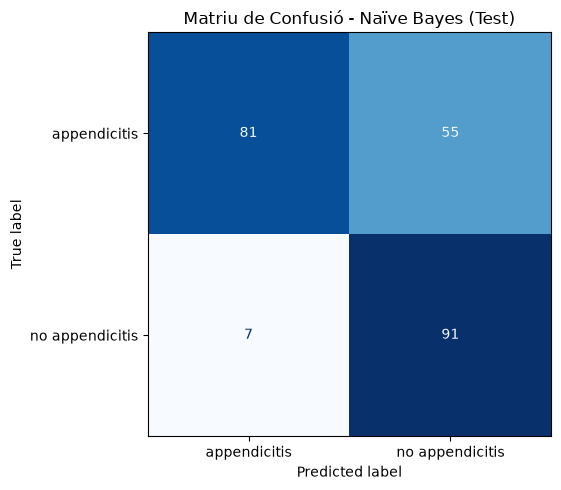

In [224]:
y_pred = millor_clsf.predict(X_test) #predicció amb dades noves
print("Resultats sobre el conjunt de Test\n")
print(classification_report(y_test, y_pred))

fig, ax = plt.subplots(figsize=(6, 5)) #matriu de confusió
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues', ax=ax, colorbar=False)
ax.set_title("Matriu de Confusió - Naïve Bayes (Test)")
plt.tight_layout()
plt.show()